In [1]:
import os
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
from collections import defaultdict
import matplotlib.pyplot as plt
from typing import Optional

from dereko_search import get_dereko_matches

In [ ]:
datadir = "../resources/developed"
sample_dir = os.path.join(datadir, "gecodb_v07_pll_ant_sample")
os.makedirs(sample_dir, exist_ok=True)

In [3]:
rng = np.random.default_rng(579372518)

This script samples a portion of compounds that may insert a pluralic linker (PLL) for manual annotation. The annotated data will further be used for investigation of the internal plural effect (IntPE) as defined by Schäfer & Pankratz 2018.

The reason the script is formatted as a notebook is because a few distribution inspections and statistical tests are provisioned, and so an interactive and step-wise manner of sampling is preferred.

The main purpose of the sample is not to investigate the IntPE (which has already been confirmed by Schäfer & Pankratz 2018) but to compute the regularity measures of the pluralic constraints as a followup to Shmalts 2026. For that, we need to be annotating a sample of PLL compounds as close to the empirical compound distribution in terms of their frequencies and linkers as possible. On the other hand, the annotation is a very time- and effort-demanding process, and so we need to additionally ensure a high informational utility of the final sample. Given a small size of the sample and a large number of N1s in the original data, we need to focus on the most representative N1s. To reduce possible influence of further constraints, we choose compounds built with N1s that attach a pluralic linker in 25-75% of cases. During regularity computation, we will be taking only compounds whose N1s do exhibit plural semantics; that means that we need to possibly increase the probability of plural semantics of N1 in the sample. Since all N1s we keep attach the pluralic linker in at least 25% of cases, we expect to see the pluralic linker (so **possibly** plural semantics) at least once in four compounds built with a given N1. We will therefore remove all N1s that build less than four compounds in the sample. Finally, to reduce the influence of the "N1 productivity problem", we clip N1s to a certain number of compounds in the sample. In the end, we strive to find a balance between faithful representation of the original population, and a wise usage of the annotators workforce.

To achieve that, we will proceed as follows:
1. Load GeCoDB_v07.
2. Keep only compounds whose N1s may attach the PLL.
3. Save the intermediate GeCoDB_v07_PLL dataset.
4. Filter out N1s that predominantly attach (N)PLLs.
5. Define the frequency class of the compounds.
6. Self-evaluation: make sure that the logarithmic frequency/productivity values are distributed identically to the labelled classes.
7. Sample up to 300 compounds pro PLL in a distribution-aware manner.
8. Clip "outlier" N1s to the 90% productivity percentile & remove N1s that build less than 4 compounds.
9. Manual cleaning.
10. Self-evaluation: make sure that the distribution of the frequency classes of the source PLL population is identical to that of the sample.
11. Extract contexts from DeReKo.
12. Format the vignettes.
13. Save the vignettes.

1. Load GeCoDB_v07.

In [4]:
# (N=277361)
gecodb_v07 = pd.read_csv(
    os.path.join(datadir, "gecodb_v07.tsv"),
    sep="\t",
    dtype=defaultdict(
        lambda: str,
        **{
            f"{prx}_freq": int
            for prx in ["comp", "n1", "n2"]
        },
        n1_prod="int",
        is_pll="bool",
        umlaut_applied="bool"
    ),
    header=0,
    index_col=0
)

gecodb_v07.sample(10)

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,is_pll,umlaut_applied,n2_lemma,n2_freq
comp_gecodb,,,,,,,,,,
energie_rationierung,Energierationierung,35,energie,1076273,530,_,False,False,rationierung,4575
urlaub_+s_beratung,Urlaubsberatung,58,urlaub,707336,357,_+s_,False,False,beratung,847488
erregung_+s_schwelle,Erregungsschwelle,27,erregung,23946,21,_+s_,False,False,schwelle,133252
wein_schale,Weinschale,33,wein,656636,570,_,False,False,schale,95543
missbrauch_+s_form,Missbrauchsform,36,missbrauch,254078,66,_+s_,False,False,form,1609109
person_+en_archiv,Personenarchiv,47,person,2324781,163,_+en_,True,False,archiv,347470
sattel_klemme,Sattelklemme,28,sattel,66527,56,_,False,False,klemme,20989
anker_werk,Ankerwerk,24,anker,72333,55,_,False,False,werk,2210537
trompete_+n_sammlung,Trompetensammlung,34,trompete,71803,60,_+n_,True,False,sammlung,425109


2. Keep only compounds whose N1s may attach the PLL.

    Since we want to study the alternation between the non-pluralic linkers (NPLLs) and PLLs, we keep all compounds with the resulting N1s both with NPLLs and PLLs.

In [5]:
# filter out N1s that may not attach pl linkers
gecodb_v07pll_n1s = gecodb_v07[gecodb_v07["is_pll"]]["n1_lemma"].unique()
gecodb_v07pll = gecodb_v07[gecodb_v07["n1_lemma"].isin(gecodb_v07pll_n1s)]

gecodb_v07pll.sample(10)

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,is_pll,umlaut_applied,n2_lemma,n2_freq
comp_gecodb,,,,,,,,,,
leib_+es_lust,Leibeslust,30,leib,196604,60,_+es_,False,False,lust,558705
stamm_+es_kunst,Stammeskunst,705,stamm,196839,329,_+es_,False,False,kunst,1608690
platte_+n_kamera,Plattenkamera,1045,platte,264291,153,_+n_,True,False,kamera,603118
wüste_+n_reiter,Wüstenreiter,21,wüste,138563,186,_+n_,True,False,reiter,233009
garten_architektur,Gartenarchitektur,1101,garten,994608,475,_,False,False,architektur,224784
ohr_fasan,Ohrfasan,94,ohr,466047,144,_,False,False,fasan,12008
hase_+n_futter,Hasenfutter,162,hase,147724,169,_+n_,True,False,futter,117379
mann_+=er_uhr,Männeruhr,82,mann,8392866,477,_+=er_,True,True,uhr,23617374
bruder_kampf,Bruderkampf,1605,bruder,932838,76,_,False,False,kampf,1498238


3. Save the intermediate GeCoDB_v07_PLL dataset.

In [ ]:
# (N=92475, PLL N=41543, NPLL N=50932, UniqN1N=890)
gecodb_v07pll.to_csv(
    os.path.join(datadir, "gecodb_v07pll.tsv"),
    sep="\t",
    header=True,
    index=True
)

4. Filter out N1s that predominantly attach (N)PLLs.

    Filtering out N1s that mostly attach only (N)PPLs is needed to decrease the influence of other factors on linker choice, and render the theorized IntPE more pronounced. For example, 'Kind' inserts the PLL in 947/1047 (90%) cases, which may indicate that there are other factors forcing the PLL to appear (we know it is because it is a person designation). A more extreme example is 'Wasser' that only attaches the PLL in 1/940 (0.1%) cases (which is due to its mass semantics). What we want is a sample of more balanced N1s that productively alternate between PLL and NPLL.

In [7]:
# filter out N1s that mostly attach pll/npll
pll_counts = pd.DataFrame({
    n1: {
        "pll": len(
            gecodb_v07pll[
                (gecodb_v07pll["n1_lemma"] == n1) &
                gecodb_v07pll["is_pll"]
            ]
        ),
        "npll": len(
            gecodb_v07pll[
                (gecodb_v07pll["n1_lemma"] == n1) &
                ~gecodb_v07pll["is_pll"]
            ]
        )
    }
    for n1 in gecodb_v07pll["n1_lemma"].unique()
}).T
pll_counts["pll_share"] = pll_counts["pll"] / pll_counts.sum(axis=1)

pll_counts

,pll,npll,pll_share
land,226,928,0.195841
kind,942,100,0.904031
wasser,1,932,0.001072
spiel,164,687,0.192714
bild,215,454,0.321375
...,...,...,...
hüne,3,3,0.500000
vorwoche,12,0,1.000000
adduktor,10,0,1.000000
kuriosität,10,0,1.000000


In [8]:
balanced_n1s = pll_counts[
    (pll_counts["pll_share"] >= 0.25) &
    (pll_counts["pll_share"] <= 0.75)
].index
balanced_n1s

Index(['bild', 'buch', 'geist', 'probe', 'gott', 'motor', 'gast', 'weg',
       'anlage', 'punkt', 'wert', 'ei', 'mitglied', 'kohle', 'maus', 'schuld',
       'strahl', 'norm', 'geschlecht', 'geburt', 'ohr', 'bad', 'ausgabe',
       'rasse', 'bett', 'lied', 'weide', 'szene', 'last', 'gut', 'korn', 'art',
       'geschenk', 'recht', 'generation', 'frage', 'schwester', 'vater',
       'abgabe', 'spur', 'asche', 'junior', 'einnahme', 'brett', 'bruder',
       'minderheit', 'kalb', 'melodie', 'kategorie', 'vorlage', 'traktor',
       'einlage', 'rate', 'anleihe', 'aue', 'witz', 'priorität', 'indikator',
       'nation', 'generator', 'unterschrift', 'frist', 'mulde', 'institution',
       'schlacke', 'kompressor', 'laus', 'tide', 'hemd', 'rüge', 'miliz',
       'waage', 'zeh', 'schlucht', 'neuheit', 'ader', 'weite', 'anhalt',
       'wehe', 'henne', 'bohle', 'made', 'kanne', 'konditor', 'rektor',
       'transformator', 'zugabe', 'elle', 'rücklage', 'karikatur', 'geste',
       'hüne'],
   

In [9]:
# (N=9731, PLL N=4546, NPLL N=5185, UniqN1N=92)
gecodb_v07pll = gecodb_v07pll[gecodb_v07pll["n1_lemma"].isin(balanced_n1s)]
gecodb_v07pll

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,is_pll,umlaut_applied,n2_lemma,n2_freq
comp_gecodb,,,,,,,,,,
bild_qualität,Bildqualität,9525,bild,3732418,672,_,False,False,qualität,940698
bild_material,Bildmaterial,13966,bild,3732418,672,_,False,False,material,698223
bild_+=er_galerie,Bildergalerie,16699,bild,3732418,672,_+er_,True,False,galerie,442177
bild_+=er_buch,Bilderbuch,40509,bild,3732418,672,_+er_,True,False,buch,2731652
bild_bearbeitung,Bildbearbeitung,9280,bild,3732418,672,_,False,False,bearbeitung,103559
...,...,...,...,...,...,...,...,...,...,...
hüne_+n_bett,Hünenbett,102,hüne,15531,8,_+n_,True,False,bett,378276
hüne_mörder,Hünemörder,1446,hüne,15531,8,_,False,False,mörder,178229
hüne_meier,Hünemeier,1041,hüne,15531,8,_,False,False,meier,228573


In [10]:
plls = [
    "_+n_", "_+en_",
    "_+e_", "_+=e_",
    "_+=_",
    "_+er_", "_+=er_"
]
all(pll in gecodb_v07pll["linker"].unique() for pll in plls)

True

5. Define the frequency class of the compounds.

    Compound frequencies are distributed very unevenly, with a long tail of low-frequency compounds. They are also built from N1s, whose frequencies are also distributed quite unevenly. Finally, N1s productivity are far from normal distribution. Given the evidence on analogical effects in German compounding (e.g. Krott et al. 2007), we find it crucial to exercise a distribution-aware sampling in order to ensure that the sample is representative of the whole population.

    To do so, we first establish an ordinal scale for each of the three abovementioned parameters by dividing the range of the their logarithmic values onto eight equal segments. Thus, three scales are produced. For example, the scale of compound frequency look as follows:

    * Class `1`: range $[3.0; 4.4)$
    * Class `2`: range $[4.4; 5.81)$
    * Class `3`: range $[5.81; 7.22)$
    * Class `4`: range $[7.22; 8.63)$
    * Class `5`: range $[8.63; 10.04)$
    * Class `6`: range $[10.04; 11.44)$
    * Class `7`: range $[11.44; 12.85)$
    * Class `8`: range $[12.85; 14.26]$

    Then, we determine the class of the compound in each of the three scales. By joining the classes, we obtain a frequency class code that summarizes the magnitude of the compound frequency, the magnitude of the N1 frequency, and the magnitude of the N1 productivity for a given compound. For example, code `4-6-3` means that the compound has a frequency in the middle of the scale (`4`), its N1 is quite frequent (`6`) but not too productive (`3`).

In [11]:
NCLASSES = 8

def get_log_scale(
    array: np.ndarray,
    nclasses: Optional[int]=NCLASSES
) -> np.ndarray:
    logs = np.log(array)
    log_scale = np.linspace(
        logs.min(),
        logs.max(),
        # x intervals => x + 1 points
        num=nclasses + 1
    )
    return log_scale


def print_scale(scale: np.ndarray) -> None:
    for i in range(len(scale) - 1):
        a = scale[i].round(2)
        b = scale[i + 1].round(2)
        bracket = "]" if i == len(scale) - 2 else ")"
        print(f"Class {i + 1}: range [{a}; {b}{bracket}")

In [12]:
cf_log_scale = get_log_scale(gecodb_v07pll["comp_freq"])
print_scale(cf_log_scale)

Class 1: range [3.0; 4.4)
Class 2: range [4.4; 5.81)
Class 3: range [5.81; 7.22)
Class 4: range [7.22; 8.63)
Class 5: range [8.63; 10.04)
Class 6: range [10.04; 11.44)
Class 7: range [11.44; 12.85)
Class 8: range [12.85; 14.26]


In [13]:
n1f_log_scale = get_log_scale(gecodb_v07pll["n1_freq"])
print_scale(n1f_log_scale)

Class 1: range [8.53; 9.41)
Class 2: range [9.41; 10.29)
Class 3: range [10.29; 11.18)
Class 4: range [11.18; 12.06)
Class 5: range [12.06; 12.95)
Class 6: range [12.95; 13.83)
Class 7: range [13.83; 14.72)
Class 8: range [14.72; 15.6]


In [14]:
n1p_log_scale = get_log_scale(gecodb_v07pll["n1_prod"])
print_scale(n1p_log_scale)

Class 1: range [2.08; 2.63)
Class 2: range [2.63; 3.19)
Class 3: range [3.19; 3.74)
Class 4: range [3.74; 4.29)
Class 5: range [4.29; 4.85)
Class 6: range [4.85; 5.4)
Class 7: range [5.4; 5.96)
Class 8: range [5.96; 6.51]


In [15]:
def get_scale_class(value: float, scale: np.ndarray) -> int:
    value_geq = value >= scale
    # find the index of the first False value -
    # this will be the class of the value on the scale
    false_indices = np.where(value_geq == False)[0]
    # geq than the last value on the scale: 
    if not len(false_indices):
        return len(scale) - 1
    else:
        return false_indices[0].item()

In [16]:
# determine frequency classes for the three parameters
# earlier: define the frequency class code directly:
# >>> def freq_class_code(cf: float, n1f: float, n1p: float) -> str:
# >>>     cf, n1f, n1p = np.log([cf, n1f, n1p])
# >>>     cf_cl = get_scale_class(cf_logs_scale, cf)
# >>>     n1f_cl = get_scale_class(n1f_logs_scale, n1f)
# >>>     n1p_cl = get_scale_class(n1p_logs_scale, n1p)
# >>>     return "-".join(map(str, [cf_cl, n1f_cl, n1p_cl]))
#
# >>> gecodb_v07pll["freq_class_code"] = gecodb_v07pll.apply(
# >>>     lambda row: freq_class_code(
# >>>         row["comp_freq"], row["n1_freq"], row["n1_prod"]
# >>>     ),
# >>>     axis=1
# >>> )
# Decomposing the process now for easier distribution inspection.
gecodb_v07pll["comp_freq_cl"] = np.log(gecodb_v07pll["comp_freq"]).map(
    lambda x: get_scale_class(x, cf_log_scale)
)
gecodb_v07pll["n1_freq_cl"] = np.log(gecodb_v07pll["n1_freq"]).map(
    lambda x: get_scale_class(x, n1f_log_scale)
)
gecodb_v07pll["n1_prod_cl"] = np.log(gecodb_v07pll["n1_prod"]).map(
    lambda x: get_scale_class(x, n1p_log_scale)
)

# determine frequency class codes
gecodb_v07pll["freq_class_code"] = (
    gecodb_v07pll["comp_freq_cl"].astype(str) + "-" +
    gecodb_v07pll["n1_freq_cl"].astype(str) + "-" +
    gecodb_v07pll["n1_prod_cl"].astype(str)
)

gecodb_v07pll.sample(10)

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,is_pll,umlaut_applied,n2_lemma,n2_freq,comp_freq_cl,n1_freq_cl,n1_prod_cl,freq_class_code
comp_gecodb,,,,,,,,,,,,,,
mitglied_+=er_entwicklung,Mitgliederentwicklung,5341,mitglied,3723961,267,_+er_,True,False,entwicklung,2347495,4,8,7,4-8-7
punkt_bild,Punktbild,45,punkt,4112282,208,_,False,False,bild,3732418,1,8,6,1-8-6
gast_redakteur,Gastredakteur,70,gast,4687625,464,_,False,False,redakteur,386116,1,8,8,1-8-8
rektor_zimmer,Rektorzimmer,89,rektor,118693,20,_,False,False,zimmer,650100,2,4,2,2-4-2
geist_+=er_wald,Geisterwald,222,geist,480796,242,_+er_,True,False,wald,1102285,2,6,7,2-6-7
maus_+=e_kino,Mäusekino,432,maus,201112,154,_+=e_,True,True,kino,733054,3,5,6,3-5-6
melodie_+n_linie,Melodienlinie,39,melodie,213118,50,_+n_,True,False,linie,1057756,1,5,4,1-5-4
motor_+en_abgas,Motorenabgas,28,motor,514731,264,_+en_,True,False,abgas,41122,1,6,7,1-6-7
korn_rumpf,Kornrumpf,421,korn,127642,114,_,False,False,rumpf,58700,3,4,5,3-4-5


6. Self-evaluation: make sure that the logarithmic frequency/productivity values are distributed identically to the labelled classes.

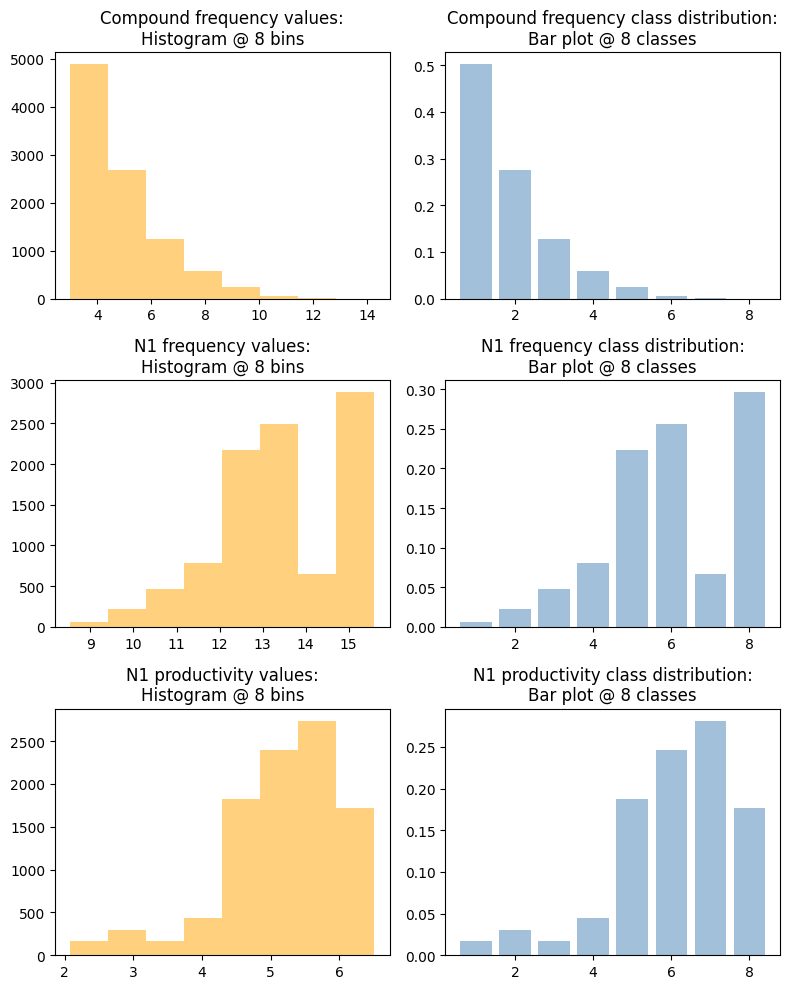

In [17]:
fig, axes = plt.subplots(3, 2, figsize=(8, 10))

all_param_shares = {}
for i, (param_name, title) in enumerate([
    ("comp_freq", "Compound frequency"),
    ("n1_freq", "N1 frequency"),
    ("n1_prod", "N1 productivity")
]):
    # log values
    axes[i, 0].hist(np.log(gecodb_v07pll[param_name]), bins=NCLASSES, color="orange", alpha=0.5)
    axes[i, 0].set_title(f"{title} values:\nHistogram @ {NCLASSES} bins")
    # class distr
    param_counts = np.unique_counts(gecodb_v07pll[f"{param_name}_cl"])
    param_shares = param_counts.counts / param_counts.counts.sum()
    axes[i, 1].bar(param_counts.values, param_shares, color="steelblue", alpha=0.5)
    axes[i, 1].set_title(f"{title} class distribution:\nBar plot @ {NCLASSES} classes")
    all_param_shares[param_name] = (param_counts.values, param_shares)

plt.tight_layout()
plt.show()

7. Sample up to 500 compounds pro PLL in a distribution-aware manner.
    
    Compute the probability of each unique frequency code and use it as a weight for the members of the corresponding compound group when sampling. 

    NB! While the distribution of each individual parameter is further divided between the values of the other two parameters, it is still preserved since the same distribution of these shards will be preserved in the sample, and then the information about the distribution of the parameter will be preserved through those. As a simplified example, let us imagine that the compound frequency class `2` takes up 20% of all compounds. The 20% are distributed between the other two parameters as follows: `2-3-4` makes 10% of all compounds, `2-4-4` -- 7%, `2-6-5` -- 2.5%, and `2-2-8` -- 0.5%. Since we will use the probabilities of these codes as weights, the final sample will feature ~10% of compounds of frequency class `2-3-4`, ~7% of `2-4-4`, ~2.5% of `2-6-5`, and ~0.5% of `2-2-8`. If we add those back together, we will see that compound frequency `2` will take up ~20% of compounds in the final sample, which is within the original distribution. Since the three codes are independent, each of the three parameters is decomposed and expressed through these three-place codes the same way.

In [18]:
# calculate prob of each frequency class; note that the prob
# is for individual frequency classes and not their compounds
gecodb_v07pll["freq_class_prob"] = 0.0
for code in gecodb_v07pll["freq_class_code"].unique():
    code_sample = gecodb_v07pll[gecodb_v07pll["freq_class_code"] == code].index
    gecodb_v07pll.loc[
        gecodb_v07pll[gecodb_v07pll["freq_class_code"] == code].index,
        "freq_class_prob"
    ] = len(code_sample) / len(gecodb_v07pll)

gecodb_v07pll.sample(10)

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,is_pll,umlaut_applied,n2_lemma,n2_freq,comp_freq_cl,n1_freq_cl,n1_prod_cl,freq_class_code,freq_class_prob
comp_gecodb,,,,,,,,,,,,,,,
gast_+=e_beschwerde,Gästebeschwerde,40,gast,4687625,464,_+=e_,True,True,beschwerde,328415,1,8,8,1-8-8,0.080464
art_+en_inventar,Arteninventar,157,art,2477614,96,_+en_,True,False,inventar,35234,2,8,5,2-8-5,0.002364
buch_anzeige,Buchanzeige,28,buch,2731652,603,_,False,False,anzeige,299827,1,8,8,1-8-8,0.080464
geist_+es_wandel,Geisteswandel,55,geist,480796,242,_+es_,False,False,wandel,343302,1,6,7,1-6-7,0.052102
ei_+=er_markt,Eiermarkt,3890,ei,320290,233,_+er_,True,False,markt,2649376,4,5,7,4-5-7,0.004727
buch_prüfer,Buchprüfer,1883,buch,2731652,603,_,False,False,prüfer,88816,4,8,8,4-8-8,0.011612
einnahme_beschaffung,Einnahmebeschaffung,142,einnahme,595736,120,_,False,False,beschaffung,64518,2,6,5,2-6-5,0.017573
kalb_+s_rücken,Kalbsrücken,1073,kalb,58051,75,_+s_,False,False,rücken,525155,3,3,5,3-3-5,0.001541
bild_autorin,Bildautorin,36,bild,3732418,672,_,False,False,autorin,355902,1,8,8,1-8-8,0.080464


In [ ]:
N_PRO_PLL = 500

all_pll_comps = []
for pll in plls:
    pll_n1s = gecodb_v07pll[
        # attention for 'Mausefalle'- and 'Sternenwiese'-like compounds
        gecodb_v07pll["is_pll"] &
        (gecodb_v07pll["linker"] == pll)
    ]["n1_lemma"].unique()
    pll_comps = gecodb_v07pll[gecodb_v07pll["n1_lemma"].isin(pll_n1s)]
    # normalize to sum up to 1
    pll_comps["freq_class_prob"] = (
        pll_comps["freq_class_prob"] / pll_comps["freq_class_prob"].sum()
    )
    if len(pll_comps) <= N_PRO_PLL:
        all_pll_comps.extend(pll_comps.index)
    else:
        pll_comps_sample = rng.choice(
            pll_comps.index,
            size=N_PRO_PLL,
            replace=False,  # prohibit repetitions
            p=pll_comps["freq_class_prob"]
        )
        all_pll_comps.extend(pll_comps_sample)

gecodb_v07pll_ant = gecodb_v07pll.loc[all_pll_comps]
gecodb_v07pll_ant

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,is_pll,umlaut_applied,n2_lemma,n2_freq,comp_freq_cl,n1_freq_cl,n1_prod_cl,freq_class_code,freq_class_prob
comp_gecodb,,,,,,,,,,,,,,,
probe_+n_analyse,Probenanalyse,77,probe,418886,358,_+n_,True,False,analyse,376083,1,5,7,1-5-7,0.046038
einnahme_+n_schätzung,Einnahmenschätzung,40,einnahme,595736,120,_+n_,True,False,schätzung,270190,1,6,5,1-6-5,0.032885
melodie_reigen,Melodiereigen,33,melodie,213118,50,_,False,False,reigen,48424,1,5,4,1-5-4,0.009968
einlage_betrag,Einlagebetrag,29,einlage,97889,47,_,False,False,betrag,417429,1,4,4,1-4-4,0.009146
ausgabe_team,Ausgabeteam,22,ausgabe,859483,198,_,False,False,team,3704600,1,6,6,1-6-6,0.042544
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
gut_+=er_produktion,Güterproduktion,381,gut,425955,153,_+=er_,True,True,produktion,752050,3,6,6,3-6-6,0.010585
korn_spitz,Kornspitz,49,korn,127642,114,_,False,False,spitz,31207,1,4,5,1-4-5,0.027027
bad_+=er_sanierung,Bädersanierung,206,bad,3368150,221,_+=er_,True,True,sanierung,941866,2,8,6,2-8-6,0.012948


8. Clip "outlier" N1s to the 90% productivity percentile & remove N1s that build less than 4 compounds.

    A few N1s build disproportionally many compounds in comparison to others. In this step, these N1s are identified, and a number of compounds built with them is dropped. As a result, all N1s in the resulting sample build no more than the 90% productivity percentile in the sample before this step.

    Also, since all N1s we kept attach the pluralic linker in at least 25% of cases, we expect to see the pluralic linker (so **possibly** plural semantics) at least once in four compounds built with a given N1. We therefore remove all N1s that build less than four compounds in the sample.

In [ ]:
n1s_0 = gecodb_v07pll_ant["n1_lemma"].unique()
n1_counts_0 = [
    len(gecodb_v07pll_ant[gecodb_v07pll_ant["n1_lemma"] == n1])
    for n1 in n1s_0
]
n1_counts_0 = pd.Series(n1_counts_0, index=n1s_0)

In [23]:
# remove N1s with less than 4 compounds
n1_less4 = n1_counts_0[n1_counts_0 < 4]
n1_less4

henne          1
zugabe         1
rate           3
ader           3
weite          2
wehe           2
hüne           1
bohle          1
miliz          1
art            3
kompressor     1
priorität      2
schlucht       1
neuheit        1
indikator      2
institution    1
generator      2
zeh            1
anhalt         1
laus           2
dtype: int64

In [ ]:
gecodb_v07pll_ant = gecodb_v07pll_ant[
    ~gecodb_v07pll_ant["n1_lemma"].isin(n1_less4.index)
]

In [ ]:
n1s_1 = gecodb_v07pll_ant["n1_lemma"].unique()
n1_counts_1 = [
    len(gecodb_v07pll_ant[gecodb_v07pll_ant["n1_lemma"] == n1])
    for n1 in n1s_1
]
n1_counts_1 = pd.Series(n1_counts_1, index=n1s_1)

In [26]:
# get 90% percentile
desc = n1_counts_1.describe(percentiles=[0.1, 0.5, 0.9])
perc_90 = desc.loc["90%"].round().astype(int)
desc

count     52.000000
mean      60.288462
std       76.877885
min        4.000000
10%        5.100000
50%       33.500000
90%      112.900000
max      400.000000
dtype: float64

In [25]:
outlier_n1s = n1_counts_1[n1_counts_1 > perc_90]
outlier_n1s

probe    118
weg      202
gast     391
bild     259
buch     305
dtype: int64

In [ ]:
# N=735
all_to_drop = []
for n1 in outlier_n1s.index:
    n1_comps = gecodb_v07pll_ant[
        gecodb_v07pll_ant["n1_lemma"] == n1
    ].index
    n_drop = outlier_n1s.loc[n1] - perc_90
    to_drop = rng.choice(n1_comps, n_drop, replace=False)
    all_to_drop.extend(to_drop)

gecodb_v07pll_ant.drop(all_to_drop, inplace=True)

In [ ]:
n1s_2 = gecodb_v07pll_ant["n1_lemma"].unique()
n1_counts_2 = [
    len(gecodb_v07pll_ant[gecodb_v07pll_ant["n1_lemma"] == n1])
    for n1 in n1s_2
]
n1_counts_2 = pd.Series(n1_counts_2, index=n1s_2)

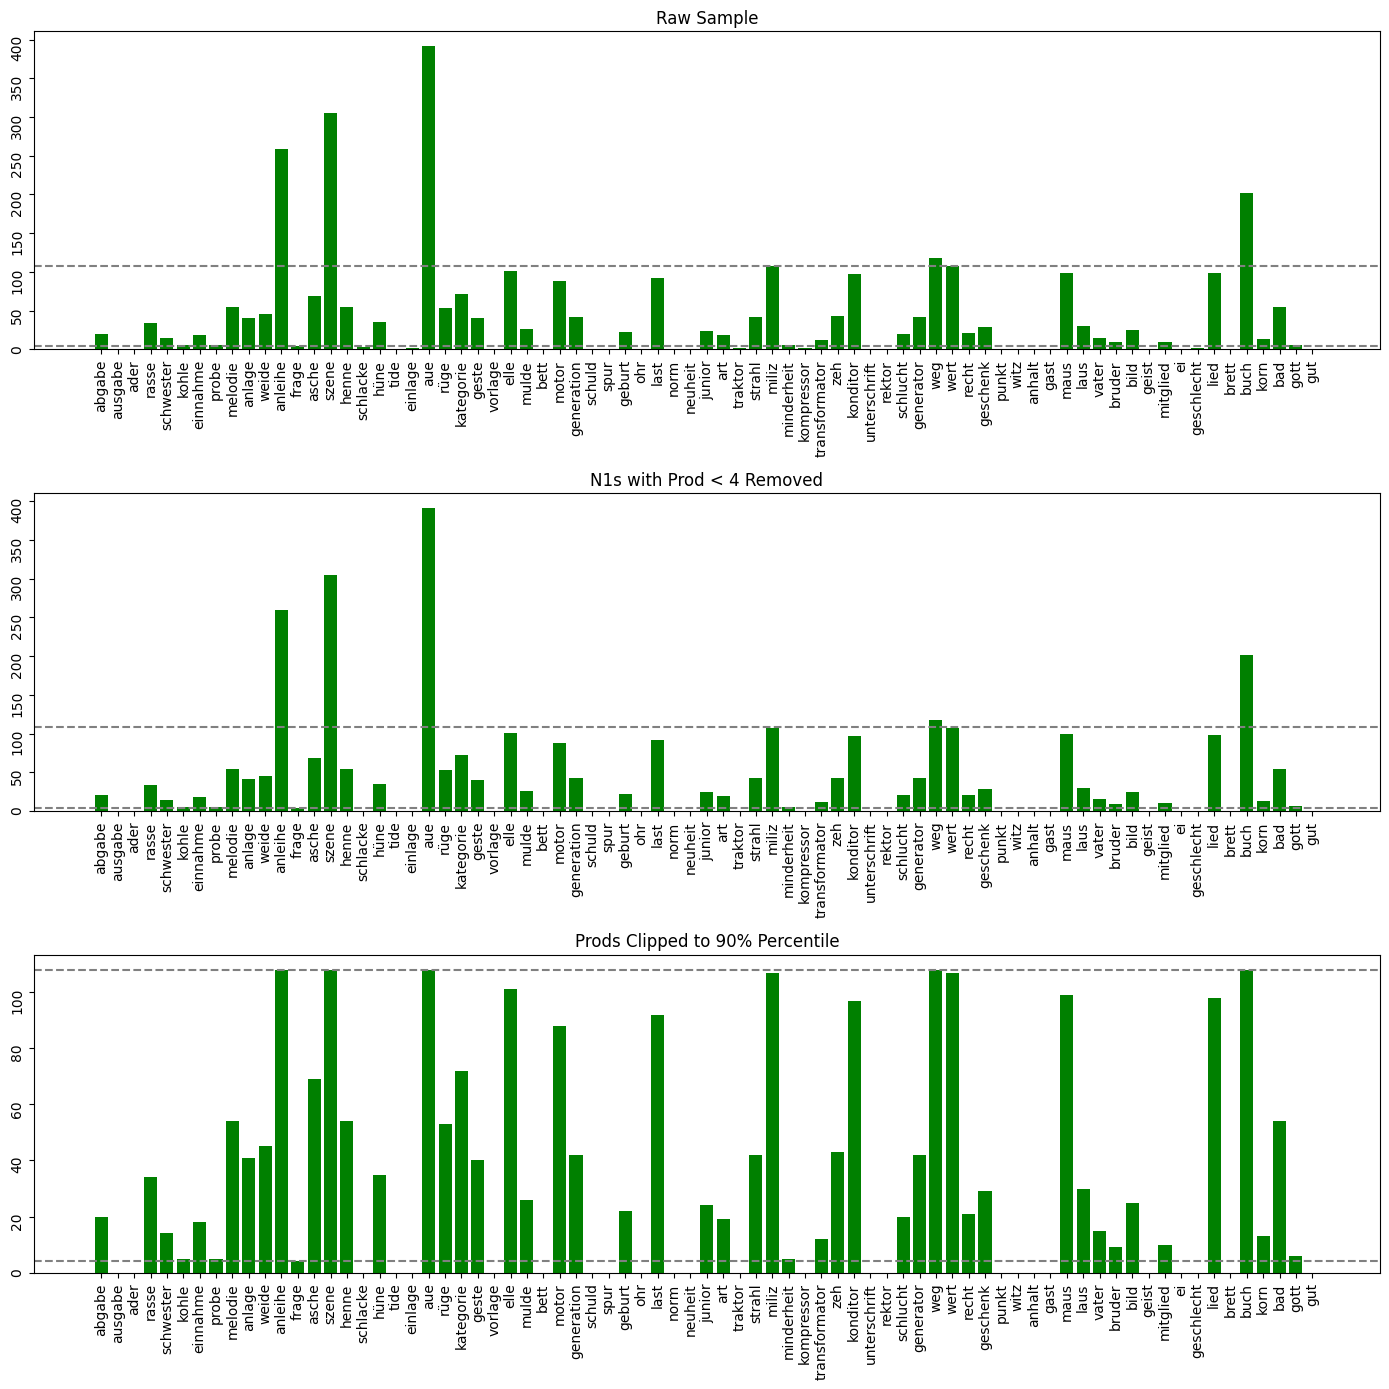

In [28]:
# compare N1 prods at different steps
fig, axes = plt.subplots(3, 1, figsize=(14, 14))

for i, (n1_counts, subtitle) in enumerate([
    (n1_counts_0, "Raw Sample"),
    (n1_counts_1, "N1s with Prod < 4 Removed"),
    (n1_counts_2, "Prods Clipped to 90% Percentile")
]):
    # filtered out by some steps
    missing_n1s = list(set(n1_counts_0.index) - set(n1_counts.index))
    n1_counts = pd.concat((n1_counts, pd.Series(0, index=missing_n1s)))
    n1_counts = n1_counts.sort_index()
    axes[i].bar(n1s_0, n1_counts, color="green")
    axes[i].axhline(y=4, color="grey", linestyle="--", linewidth=1.5)
    axes[i].axhline(y=perc_90, color="grey", linestyle="--", linewidth=1.5)
    axes[i].set_title(subtitle)
    axes[i].tick_params(rotation=90)

plt.tight_layout()
plt.show()

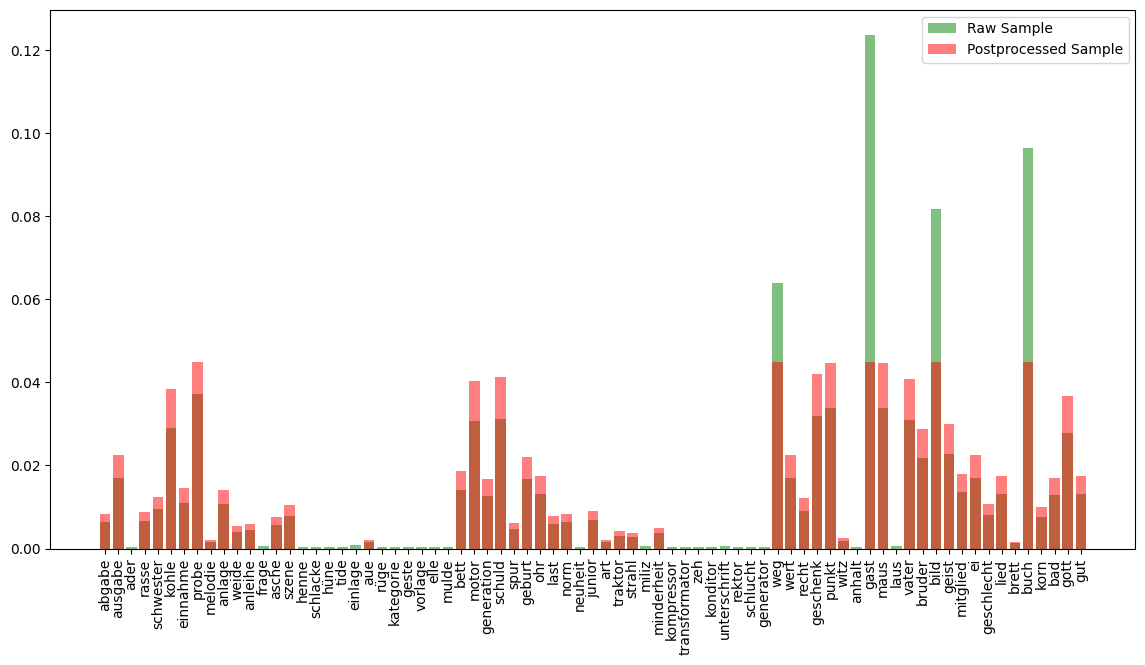

In [29]:
fig, ax = plt.subplots(figsize=(14, 7))

n1_counts_0 = n1_counts_0 / n1_counts_0.sum()
n1_counts_2 = pd.concat((
    n1_counts_2,
    pd.Series(0, index=list(
            set(n1_counts_0.index) - set(n1_counts_2.index)
        )
    )
))
n1_counts_2 = n1_counts_2 / n1_counts_2.sum()

ax.bar(n1_counts_0.index, n1_counts_0, color="green", alpha=0.5, label="Raw Sample")
ax.bar(n1_counts_2.index, n1_counts_2, color="red", alpha=0.5, label="Postprocessed Sample")
ax.legend()

plt.xticks(rotation=90)
plt.show()

9. Manual cleaning.

    In this step, we manually remove the entries in the intermediate dataset that are misanalyses of similar. Many thanks to Reinhild Barkey for a thorough inspection of the intermediate dataset.

In [ ]:
to_remove = [
    # Adverb
    "vater_los", "weg_los",
    # Derivation
    "weg_fahrer", "weg_läufer", "weg_transport", "weg_werfer", "weg_wurf",
    # Eigenname
    "gast_mann", "asche_meier", "baddeck", "bad_werk", "buch_hain", "buch_halt",
    "bett_rum", "bruder_müller", "henne_vogel", "lied_ecke", "vater_laus",
    "weg_schneider", "bad_städter", "weg_rat",
    # nominslisiertes Verb
    "weg_lese",
    # falsche Trennung
    "bad_egel",  # bad_e_gel
    "buch_+s_busch",    # buchs_busch
    "buch_+s_hecke",    # buchs_hecke
    "buch_+s_kranz",    # buchs_kranz
    # nominalisiertes Verb
    "weg_rennen", "weg_schlummer",
    # typo
    "gast_gerber",  # Gastgeber
    "weg_+e_fährte",    # Weggefährte
    "weg_+e_rand"   # Wegrand/Wegesrand
]

to_remove_upd1 = [
    # Eigenname o.ä.
    "buch_horn", "gott_wein", "weg_horn", "buch_mühle", "gut_+s_kirche",
    "vater_spur", "bruder_garten"
    # Missanalyse + Derivation
    "weg_schleiche",
    # ???
    "maus_+=e_vater"
]

to_remove_upd2 = [
    # Eigenname o.ä.
    "geist_+er_meister", "hüne_feld", "bruder_kirche",
    # Derivation
    "weg_schauer"
]

to_remove.extend(to_remove_upd1)
to_remove.extend(to_remove_upd2)
to_remove = [
    g for g in to_remove
    if g in gecodb_v07pll_ant.index
]
gecodb_v07pll_ant.drop(to_remove, inplace=True)

In [ ]:
gecodb_v07pll_ant

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,is_pll,umlaut_applied,n2_lemma,n2_freq,comp_freq_cl,n1_freq_cl,n1_prod_cl,freq_class_code,freq_class_prob
comp_gecodb,,,,,,,,,,,,,,,
abgabe_regelung,Abgaberegelung,63,abgabe,189346,116,_,False,False,regelung,669527,1,5,5,1-5-5,0.019525
ausgabe_wut,Ausgabewut,30,ausgabe,859483,198,_,False,False,wut,219328,1,6,6,1-6-6,0.042544
rasse_+n_kategorie,Rassenkategorie,21,rasse,98440,109,_+n_,True,False,kategorie,381856,1,4,5,1-4-5,0.027027
rasse_+n_gegensatz,Rassengegensatz,76,rasse,98440,109,_+n_,True,False,gegensatz,557912,1,4,5,1-4-5,0.027027
schwester_schule,Schwesterschule,85,schwester,625958,117,_,False,False,schule,4221314,2,6,5,2-6-5,0.017573
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
buch_+=er_tüte,Büchertüte,42,buch,2731652,603,_+=er_,True,True,tüte,103256,1,8,8,1-8-8,0.080464
gut_+=er_beförderung,Güterbeförderung,310,gut,425955,153,_+=er_,True,True,beförderung,62581,2,6,6,2-6-6,0.023841
gott_+=er_gesellschaft,Göttergesellschaft,22,gott,973846,257,_+=er_,True,True,gesellschaft,1975885,1,6,7,1-6-7,0.052102


10. Self-evaluation: make sure that the distribution of the linker and the frequency classes of the source PLL population is identical to that of the sample.

    The distribution of the linkers, as well as the distributions of compound frequency, N1 frequency, and N1 productivity are identical within the source population of compounds built from N1s that attach the PLL in 25-75% of their compounds (N=9731), and the final sample (N=2389).

    That means that we managed to find a balance between the distribution-faithful sampling that represents the real data in an adequate manner (as demonstrated in this step), and the required preprocessing that handled too (un)productive N1s (see step 9).

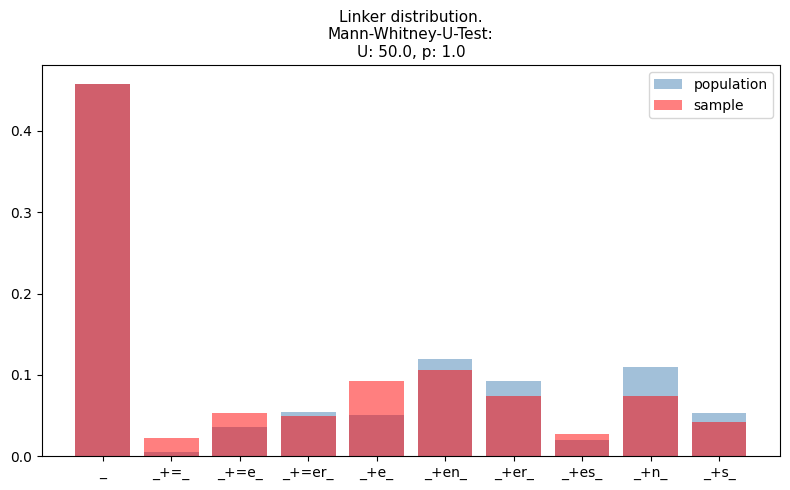

In [ ]:
# check if the distribution of the linkers is identical
linker_counts = np.unique_counts(gecodb_v07pll["linker"])
linker_shares = linker_counts.counts / linker_counts.counts.sum()

linker_counts_ant = np.unique_counts(gecodb_v07pll_ant["linker"])
linker_shares_ant = linker_counts_ant.counts / linker_counts_ant.counts.sum()

_, ax = plt.subplots(figsize=(8, 5))
ax.bar(linker_counts.values, linker_shares, color="steelblue", alpha=0.5, label="population")
ax.bar(linker_counts_ant.values, linker_shares_ant, color="red", alpha=0.5, label="sample")
ax.legend()

# test for identical distributions;
# p > 0.05 => the distributions are identical
mwu = mannwhitneyu(linker_shares, linker_shares_ant)
plt.title(
    "Linker distribution.\n"
    "Mann-Whitney-U-Test:\n"
    f"U: {mwu.statistic}, p: {mwu.pvalue.round(3)}",
    fontsize=11
)
plt.tight_layout()
plt.savefig(
    os.path.join(sample_dir, "linker_distr.png"),
    format="png",
    dpi="figure"
)
plt.show()

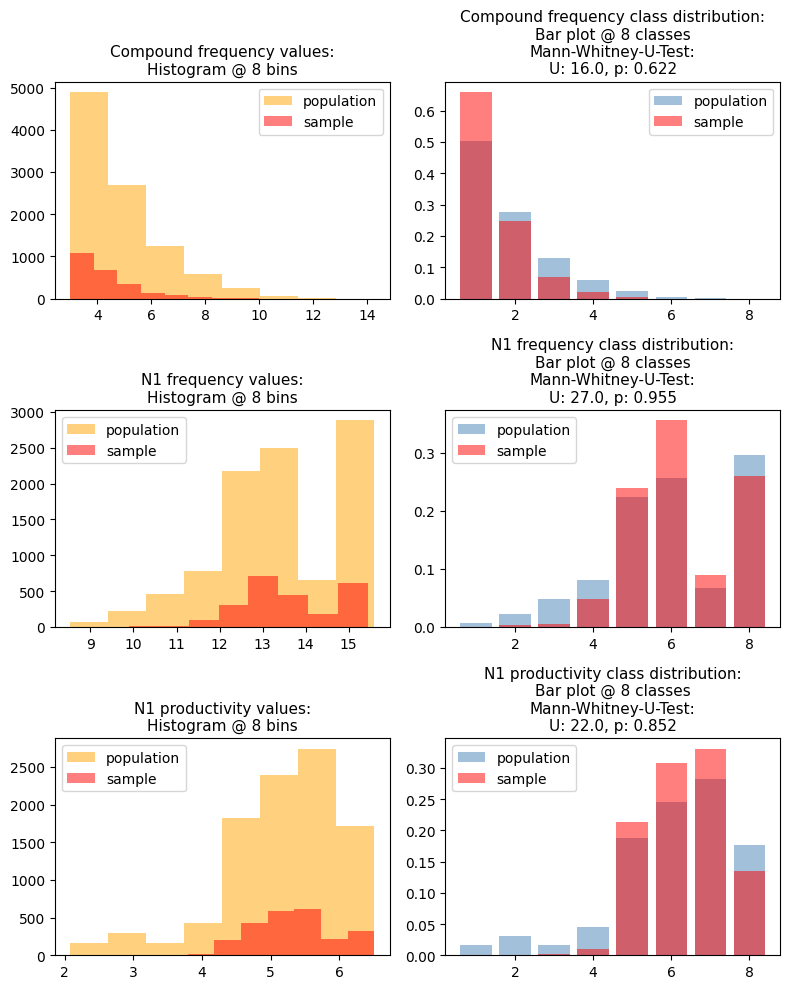

In [ ]:
# show the distribution of individual parameter log values
# vs the frequency code probs: whole population & sample
fig, axes = plt.subplots(3, 2, figsize=(8, 10))

for i, (param_name, title) in enumerate([
    ("comp_freq", "Compound frequency"),
    ("n1_freq", "N1 frequency"),
    ("n1_prod", "N1 productivity")
]):
    # log values: population vs sample, respectively
    axes[i, 0].hist(np.log(gecodb_v07pll[param_name]), bins=NCLASSES, color="orange", alpha=0.5, label="population")
    axes[i, 0].hist(np.log(gecodb_v07pll_ant[param_name]), bins=NCLASSES, color="red", alpha=0.5, label="sample")
    
    axes[i, 0].set_title(f"{title} values:\nHistogram @ {NCLASSES} bins", fontsize=11)

    # class distr: population vs sample, respectively
    axes[i, 1].bar(*all_param_shares[param_name], color="steelblue", alpha=0.5, label="population")
    param_counts_ant = np.unique_counts(gecodb_v07pll_ant[f"{param_name}_cl"])
    param_shares_ant = param_counts_ant.counts / param_counts_ant.counts.sum()
    axes[i, 1].bar(param_counts_ant.values, param_shares_ant, color="red", alpha=0.5, label="sample")
    
    axes[i, 0].legend()
    axes[i, 1].legend()

    # test for identical distributions;
    # p > 0.05 => the distributions are identical
    mwu = mannwhitneyu(all_param_shares[param_name][1], param_shares_ant)
    axes[i, 1].set_title(
        f"{title} class distribution:\n"
        f"Bar plot @ {NCLASSES} classes\n"
        "Mann-Whitney-U-Test:\n"
        f"U: {mwu.statistic}, p: {mwu.pvalue.round(3)}",
        fontsize=11
    )

plt.tight_layout()
plt.savefig(
    os.path.join(sample_dir, "frequency_distrs.png"),
    format="png",
    dpi="figure"
)
plt.show()

In [ ]:
# save intermediate sample
# (N=2389, PLL N=1119, NPLL N=1270, UniqN1N=50)
gecodb_v07pll_ant.to_csv(
    os.path.join(sample_dir, "sample.tsv"),
    sep="\t",
    header=True,
    index=True
)

10. Extract contexts from DeReKo.

In [ ]:
input_lemmata = gecodb_v07pll_ant["comp_lemma"].values.tolist()
matches = get_dereko_matches(input_lemmata, from_nb=True, nb_depth=1)

11. Format the dataset.

    We will be collection annotations concerning the singular/plural meaning of N1. We will have four categories:
    * Not countable / generic: 'Holzbrett', 'Pflegedienst', 'Buchhandel'
    * Unambiguously Sg: 'Buchdeckel', 'Landesbank'
    * Ambiguous: 'Kinderwagen', 'Zeitungsleser'
    * Unambiguously Pl: 'Blumenstrauß', 'Bücherregal'
    * None

    For the convenience of the annotators, we will prepare vignettes for them to fill in. Each vignette will consist of the compound entry and fields for marking the assigned category, a comment field, and three contexts.

In [ ]:
N_CONTX = 3

vignette_template = """\
# {i}: {lemma}

Pluralbedeutung:\t\tNein []\t\tJa []\t\tUndeutlich []\t\tDistributiv []\t\tUnzählbar []
Fehlererklärung: ggf. hier erklären
Bemerkung: ggf. hier einfügen

{contexts}

========================================


"""

def make_vignette(lemma: str, i: int) -> str:
    contexts = matches.get(lemma, {})
    if not len(contexts):
        return
    # merge & deduplicate
    contexts = [
        f"... {c['lc']}{c['match']}{c['rc']} ..."
        for c in contexts
    ]
    contexts = list(set(contexts))
    if len(contexts) > N_CONTX:
        contexts = rng.choice(contexts, N_CONTX, replace=False)
    contexts = [
        f"Kontext {j + 1}: {c}"
        for j, c in enumerate(contexts)
    ]
    vignette = vignette_template.format(
        i=i,
        lemma=lemma,
        contexts="\n\n".join(contexts)
    )
    return vignette

In [30]:
rng.shuffle(input_lemmata)
vignettes = []
i = 1
for lemma in input_lemmata:
    vignette = make_vignette(lemma, i)
    if not vignette:
        continue
    vignettes.append(vignette)
    i += 1

In [31]:
print(vignettes[345])

# 346: Körnerpark

Konkrete Lesung:		Ja []		Nein []
Pluralbedeutung:		Nein []		Vllt []		Ja []		unzutreffend []
Fehler: ggf. hier erklären
Bemerkung: ggf. hier einfügen

Kontext 1: ... im Volkspark Friedrichshain, tgl. 10 -1 Uhr  Prater: Kastanienallee 7-9, bei schönem Wetter tgl. ab 12 Uhr. Herz-Jesu-Kirche: Fehrbelliner Str. 99, So 7.30 und 9.30 Uhr Heilige Messe. Galerie im Körnerpark: Di-So 10-18 Uhr  ------------------------------  Foto: Harald Schrott, 42, hat gerade "Die Kinder von Blankenese" gedreht. Jetzt steht er für den Wiener "Tatort" vor der Kamera. Foto: Ort interessanter Ausstellungen: der Hamburger ...

Kontext 2: ... 5 Jahren. So 16 Uhr, Planetarium am Insulaner, Munsterdamm 90, Eintritt 6 Euro, ermäßigt 4 Euro. Kasbek - Klezmer und Co. Eine Begegnung der Kulturen bietet Berlins dienstälteste Klezmergruppe im Neuköllner Körnerpark. Schierker Straße 8, Sa 18 Uhr, Eintritt frei. Alles anders. Spielerisch das Anderssein erleben, Gebärdensprache probieren oder im Sprachlab

12. Save the dataset.

In [32]:
with open(
    os.path.join(sample_dir, "vignettes.txt"),
    "w",
    encoding="utf-8"
) as out:
    for vignette in vignettes:
        out.write(vignette)

In [33]:
# found matches for all compounds
i - 1 == len(input_lemmata)

True

Also save a subsample of 100 compounds for me to annotate myself to understand the data better and validate the adequacy of the proposed categories.

In [34]:
N_ATTEMPT = 1

vignettes_100er = rng.choice(vignettes, 100, replace=False)
with open(
    os.path.join(sample_dir, f"vignettes_100er_{N_ATTEMPT}.txt"),
    "w",
    encoding="utf-8"
) as out:
    for vignette in vignettes_100er:
        out.write(vignette)